# CLADES Validation Under Noise

This notebook runs the CLADES-style (clonaltrans) metacloning validation pipeline on noised datasets (Normal, Uniform, and Combined) to evaluate the robustness of the algorithm to technical noise.

We measure the accuracy by comparing the calculated metaclones against the ground-truth labels using the **Adjusted Rand Index (ARI)** (where 1.0 represents perfect recovery of the original metaclones).


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from anndata import AnnData
import time
import warnings
warnings.filterwarnings('ignore')

# Predefined validation and CLADES functions imported from chronoclone package
from chronoclone import (
    load_all_noise_data,
    load_combined_noise_data,
    run_clades_validation
)

# =========================================================
# Configuration
# =========================================================

STANDARD_DIR = 'simulated_data/Standard'
ALL_NOISE_DIR = 'simulated_data/All_Noise'
COMBINED_NOISE_DIR = 'simulated_data/Combined_Noise'

time_cols = ['0', '4', '9', '15']
DAYS_CTRL = ['Day0', 'Day4', 'Day9', 'Day15']
pop = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk_prog', 'MEMP',
       'GMP', 'GMDP', 'Mast_prog', 'Baso_prog', 'Neu_prog', 'DC_prog', 'Mono_prog']
vec = ['Day' + j + '_Cluster' + i for i in pop for j in time_cols]

print("Setup completed. Pop size:", len(pop), "Timepoints:", len(time_cols))


Setup completed. Pop size: 13 Timepoints: 4


## Metacloning with CLADES Method

All helper functions and pipeline steps for CLADES-style metacloning are defined inside the `chronoclone` package directory (under `chronoclone/validation.py`).

The CLADES method performs the following steps on raw clone counts:
1. Filters out clones with less than 3 cells.
2. Filters out features with no cells.
3. Runs PCA.
4. Builds a k-NN neighbor graph (n_neighbors=10, n_pcs=50).
5. Computes UMAP coordinates.
6. Clusters clones using Leiden clustering (resolution=0.25) to identify metaclones.


## Single Noise Accuracy Sweeps (Every 10%)

First, we run the validation sweeps on single noise types (Normal and Uniform) at 10% increments to evaluate the general trends.


In [2]:
levels = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

print("=== Running CLADES Normal Noise Sweeps (0% Uniform) ===")
normal_ari = []
for pct in levels:
    t0 = time.time()
    final_table = load_all_noise_data(pct, 'gaussian')
    ari = run_clades_validation(final_table)
    normal_ari.append(ari)
    print(f"  Normal noise {pct}%: ARI = {ari:.4f} (took {time.time()-t0:.2f} s)")

print("\n=== Running CLADES Uniform Noise Sweeps (0% Normal) ===")
uniform_ari = []
for pct in levels:
    t0 = time.time()
    final_table = load_all_noise_data(pct, 'uniform')
    ari = run_clades_validation(final_table)
    uniform_ari.append(ari)
    print(f"  Uniform noise {pct}%: ARI = {ari:.4f} (took {time.time()-t0:.2f} s)")


=== Running CLADES Normal Noise Sweeps (0% Uniform) ===


2026-06-25 22:36:15.495077: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-25 22:36:17.156328: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-06-25 22:36:19.455118: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


  Normal noise 0%: ARI = 0.6033 (took 18.38 s)
  Normal noise 10%: ARI = 0.5494 (took 0.85 s)
  Normal noise 20%: ARI = 0.4276 (took 0.83 s)
  Normal noise 30%: ARI = 0.2832 (took 0.87 s)
  Normal noise 40%: ARI = 0.2815 (took 0.96 s)
  Normal noise 50%: ARI = 0.2166 (took 0.86 s)
  Normal noise 60%: ARI = 0.1888 (took 0.92 s)
  Normal noise 70%: ARI = 0.1658 (took 0.86 s)
  Normal noise 80%: ARI = 0.1296 (took 0.93 s)
  Normal noise 90%: ARI = 0.1002 (took 0.90 s)
  Normal noise 100%: ARI = 0.1304 (took 0.89 s)

=== Running CLADES Uniform Noise Sweeps (0% Normal) ===
  Uniform noise 0%: ARI = 0.6033 (took 2.66 s)
  Uniform noise 10%: ARI = 0.4937 (took 0.83 s)
  Uniform noise 20%: ARI = 0.4520 (took 0.84 s)
  Uniform noise 30%: ARI = 0.5487 (took 0.85 s)
  Uniform noise 40%: ARI = 0.4683 (took 0.84 s)
  Uniform noise 50%: ARI = 0.5321 (took 0.86 s)
  Uniform noise 60%: ARI = 0.4594 (took 0.89 s)
  Uniform noise 70%: ARI = 0.3476 (took 0.87 s)
  Uniform noise 80%: ARI = 0.2226 (took 0.

### Plotting Single Noise Robustness (Every 10%)


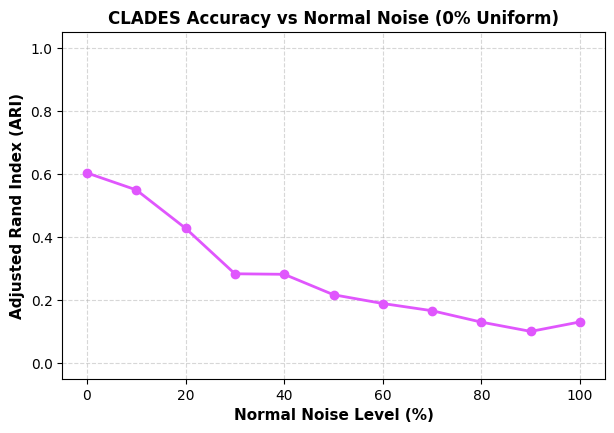

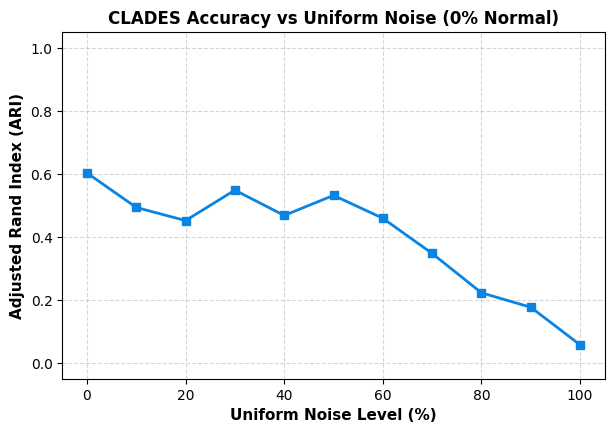

In [3]:
# Plot 1: Normal Noise vs ARI
plt.figure(figsize=(7, 4.5))
plt.plot(levels, normal_ari, marker='o', linestyle='-', color='#e056fd', linewidth=2)
plt.xlabel("Normal Noise Level (%)", fontsize=11, fontweight='bold')
plt.ylabel("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')
plt.title("CLADES Accuracy vs Normal Noise (0% Uniform)", fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.ylim(-0.05, 1.05)
plt.show()

# Plot 2: Uniform Noise vs ARI
plt.figure(figsize=(7, 4.5))
plt.plot(levels, uniform_ari, marker='s', linestyle='-', color='#0984e3', linewidth=2)
plt.xlabel("Uniform Noise Level (%)", fontsize=11, fontweight='bold')
plt.ylabel("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')
plt.title("CLADES Accuracy vs Uniform Noise (0% Normal)", fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.ylim(-0.05, 1.05)
plt.show()


## Combined Noise Grid Evaluation (6x6)

Running CLADES on the combined noise grid at 20% intervals.


In [4]:
grid_levels = [0, 20, 40, 60, 80, 100]

print("=== Running CLADES Combined Noise Grid Validation ===")
combined_grid = np.zeros((len(grid_levels), len(grid_levels)))

for i, g_pct in enumerate(grid_levels):
    for j, u_pct in enumerate(grid_levels):
        t0 = time.time()
        final_table = load_combined_noise_data(g_pct, u_pct)
        ari = run_clades_validation(final_table)
        combined_grid[i, j] = ari
        print(f"  Grid [Normal={g_pct}%, Uniform={u_pct}%]: ARI = {ari:.4f} (took {time.time()-t0:.2f} s)")


=== Running CLADES Combined Noise Grid Validation ===
  Grid [Normal=0%, Uniform=0%]: ARI = 0.6033 (took 2.66 s)
  Grid [Normal=0%, Uniform=20%]: ARI = 0.4578 (took 0.84 s)
  Grid [Normal=0%, Uniform=40%]: ARI = 0.5574 (took 0.88 s)
  Grid [Normal=0%, Uniform=60%]: ARI = 0.4828 (took 0.86 s)
  Grid [Normal=0%, Uniform=80%]: ARI = 0.2470 (took 0.90 s)
  Grid [Normal=0%, Uniform=100%]: ARI = 0.0434 (took 0.95 s)
  Grid [Normal=20%, Uniform=0%]: ARI = 0.4305 (took 0.84 s)
  Grid [Normal=20%, Uniform=20%]: ARI = 0.4426 (took 0.85 s)
  Grid [Normal=20%, Uniform=40%]: ARI = 0.4124 (took 0.84 s)
  Grid [Normal=20%, Uniform=60%]: ARI = 0.3010 (took 0.85 s)
  Grid [Normal=20%, Uniform=80%]: ARI = 0.2121 (took 0.91 s)
  Grid [Normal=20%, Uniform=100%]: ARI = 0.0458 (took 0.98 s)
  Grid [Normal=40%, Uniform=0%]: ARI = 0.2863 (took 0.87 s)
  Grid [Normal=40%, Uniform=20%]: ARI = 0.2718 (took 0.84 s)
  Grid [Normal=40%, Uniform=40%]: ARI = 0.2402 (took 0.88 s)
  Grid [Normal=40%, Uniform=60%]: ARI 

### Combined Noise Robustness Heatmap (6x6)


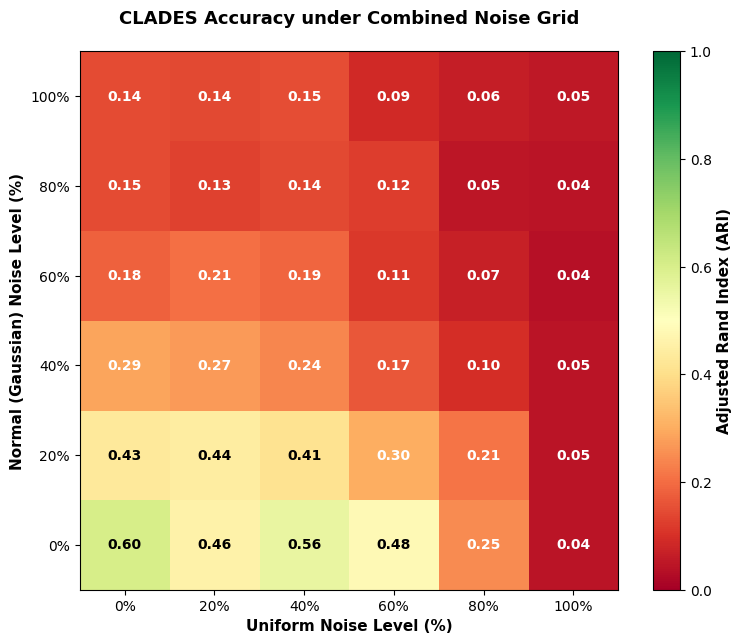

In [5]:
plt.figure(figsize=(8, 6.5))
im = plt.imshow(combined_grid, cmap='RdYlGn', origin='lower', vmin=0, vmax=1)
cbar = plt.colorbar(im)
cbar.set_label("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')

plt.xticks(range(len(grid_levels)), [f"{x}%" for x in grid_levels])
plt.yticks(range(len(grid_levels)), [f"{x}%" for x in grid_levels])
plt.xlabel("Uniform Noise Level (%)", fontsize=11, fontweight='bold')
plt.ylabel("Normal (Gaussian) Noise Level (%)", fontsize=11, fontweight='bold')
plt.title("CLADES Accuracy under Combined Noise Grid", fontsize=13, fontweight='bold', pad=20)

# Annotate values inside cells
for i in range(len(grid_levels)):
    for j in range(len(grid_levels)):
        val = combined_grid[i, j]
        text_color = "white" if val < 0.35 or val > 0.8 else "black"
        plt.text(j, i, f"{val:.2f}", ha="center", va="center", 
                 color=text_color, fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


## Full Single Noise Sweeps (Every 2%)

Running CLADES validation at every 2% noise level (0%, 2%, 4%, ..., 100%) for both Normal and Uniform noise independently.


In [6]:
all_levels = list(range(0, 101, 2))  # 51 levels

print("=== Full Normal Noise Sweep (every 2%, 0% Uniform) ===")
full_normal_ari = []
for pct in all_levels:
    t0 = time.time()
    ft = load_all_noise_data(pct, 'gaussian')
    ari = run_clades_validation(ft)
    full_normal_ari.append(ari)
    print(f"  Normal {pct}%: ARI = {ari:.4f} ({time.time()-t0:.1f}s)")

print("\n=== Full Uniform Noise Sweep (every 2%, 0% Normal) ===")
full_uniform_ari = []
for pct in all_levels:
    t0 = time.time()
    ft = load_all_noise_data(pct, 'uniform')
    ari = run_clades_validation(ft)
    full_uniform_ari.append(ari)
    print(f"  Uniform {pct}%: ARI = {ari:.4f} ({time.time()-t0:.1f}s)")


=== Full Normal Noise Sweep (every 2%, 0% Uniform) ===


  Normal 0%: ARI = 0.6033 (2.7s)
  Normal 2%: ARI = 0.5177 (0.9s)
  Normal 4%: ARI = 0.5504 (0.8s)
  Normal 6%: ARI = 0.5429 (0.8s)
  Normal 8%: ARI = 0.5161 (0.8s)
  Normal 10%: ARI = 0.5494 (0.8s)
  Normal 12%: ARI = 0.5605 (0.8s)
  Normal 14%: ARI = 0.5355 (0.8s)
  Normal 16%: ARI = 0.4699 (0.8s)
  Normal 18%: ARI = 0.5243 (0.8s)
  Normal 20%: ARI = 0.4276 (0.8s)
  Normal 22%: ARI = 0.4636 (0.8s)
  Normal 24%: ARI = 0.3774 (0.8s)
  Normal 26%: ARI = 0.3547 (0.9s)
  Normal 28%: ARI = 0.3511 (0.9s)
  Normal 30%: ARI = 0.2832 (0.9s)
  Normal 32%: ARI = 0.2569 (0.9s)
  Normal 34%: ARI = 0.2734 (0.9s)
  Normal 36%: ARI = 0.2827 (0.9s)
  Normal 38%: ARI = 0.2675 (1.0s)
  Normal 40%: ARI = 0.2815 (0.9s)
  Normal 42%: ARI = 0.2414 (0.9s)
  Normal 44%: ARI = 0.2072 (0.9s)
  Normal 46%: ARI = 0.2344 (0.9s)
  Normal 48%: ARI = 0.1965 (0.9s)
  Normal 50%: ARI = 0.2166 (0.9s)
  Normal 52%: ARI = 0.1761 (0.9s)
  Normal 54%: ARI = 0.1861 (0.9s)
  Normal 56%: ARI = 0.1991 (0.9s)
  Normal 58%: ARI =

### Full Single Noise Plots (Every 2%)


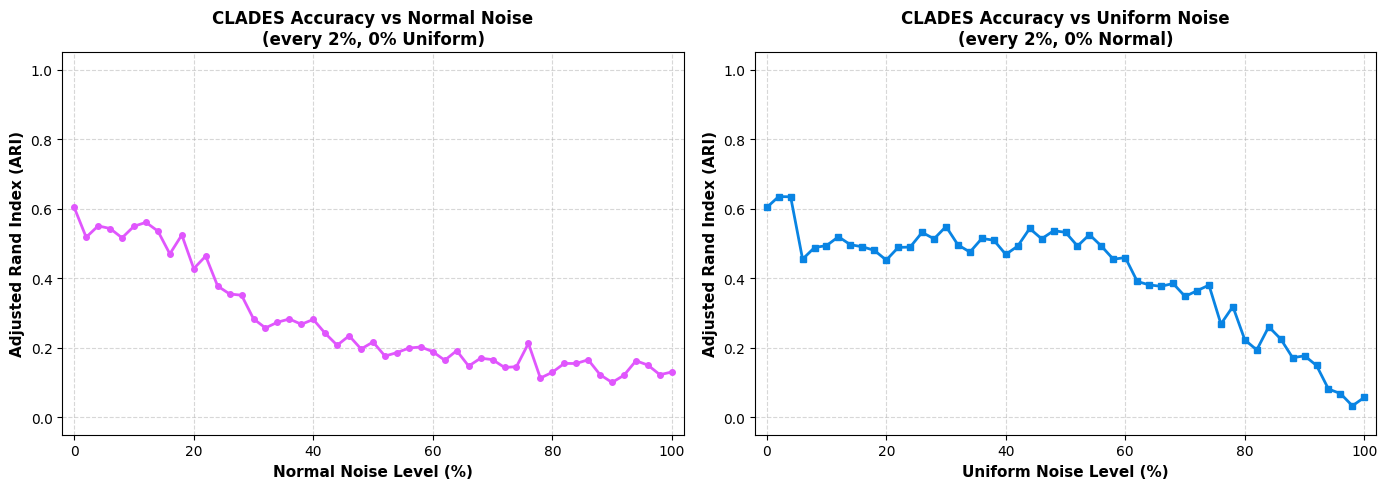

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Full Normal Noise vs ARI
axes[0].plot(all_levels, full_normal_ari, marker='o', linestyle='-', color='#e056fd', linewidth=2, markersize=4)
axes[0].set_xlabel("Normal Noise Level (%)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')
axes[0].set_title("CLADES Accuracy vs Normal Noise\n(every 2%, 0% Uniform)", fontsize=12, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_xlim(-2, 102)

# Plot 2: Full Uniform Noise vs ARI
axes[1].plot(all_levels, full_uniform_ari, marker='s', linestyle='-', color='#0984e3', linewidth=2, markersize=4)
axes[1].set_xlabel("Uniform Noise Level (%)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')
axes[1].set_title("CLADES Accuracy vs Uniform Noise\n(every 2%, 0% Normal)", fontsize=12, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_xlim(-2, 102)

plt.tight_layout()
plt.show()


## Full Combined Noise Grid (Every 2%)

Running CLADES validation at every 2% noise level for both Normal and Uniform noise simultaneously.
This creates a $51 \times 51 = 2601$ grid of evaluations.


In [8]:
all_levels_combined = list(range(0, 101, 2))  # 51 levels
n = len(all_levels_combined)

print(f"=== Full Combined Noise Grid ({n}x{n} = {n*n} evaluations) ===")
full_combined_grid = np.zeros((n, n))

total_runs = n * n
run_count = 0

for i, g_pct in enumerate(all_levels_combined):
    for j, u_pct in enumerate(all_levels_combined):
        t0 = time.time()
        ft = load_combined_noise_data(g_pct, u_pct)
        ari = run_clades_validation(ft)
        full_combined_grid[i, j] = ari
        run_count += 1
        if run_count % 100 == 0 or run_count <= 3:
            elapsed = time.time() - t0
            print(f"  [{run_count}/{total_runs}] Normal={g_pct}%, Uniform={u_pct}%: ARI={ari:.4f} ({elapsed:.1f}s)")

print(f"\nAll {total_runs} evaluations complete!")


=== Full Combined Noise Grid (51x51 = 2601 evaluations) ===
  [1/2601] Normal=0%, Uniform=0%: ARI=0.6033 (2.7s)
  [2/2601] Normal=0%, Uniform=2%: ARI=0.6361 (0.8s)
  [3/2601] Normal=0%, Uniform=4%: ARI=0.6334 (0.8s)
  [100/2601] Normal=2%, Uniform=96%: ARI=0.0704 (0.9s)
  [200/2601] Normal=6%, Uniform=92%: ARI=0.1436 (0.9s)
  [300/2601] Normal=10%, Uniform=88%: ARI=0.1691 (0.9s)
  [400/2601] Normal=14%, Uniform=84%: ARI=0.1707 (0.9s)
  [500/2601] Normal=18%, Uniform=80%: ARI=0.1646 (0.9s)
  [600/2601] Normal=22%, Uniform=76%: ARI=0.2633 (0.9s)
  [700/2601] Normal=26%, Uniform=72%: ARI=0.2809 (0.9s)
  [800/2601] Normal=30%, Uniform=68%: ARI=0.2025 (0.9s)
  [900/2601] Normal=34%, Uniform=64%: ARI=0.2237 (0.9s)
  [1000/2601] Normal=38%, Uniform=60%: ARI=0.1948 (0.9s)
  [1100/2601] Normal=42%, Uniform=56%: ARI=0.2378 (0.9s)
  [1200/2601] Normal=46%, Uniform=52%: ARI=0.1599 (1.0s)
  [1300/2601] Normal=50%, Uniform=48%: ARI=0.1964 (0.9s)
  [1400/2601] Normal=54%, Uniform=44%: ARI=0.1902 (0.9

### Full Combined Noise Heatmap (Every 2%)


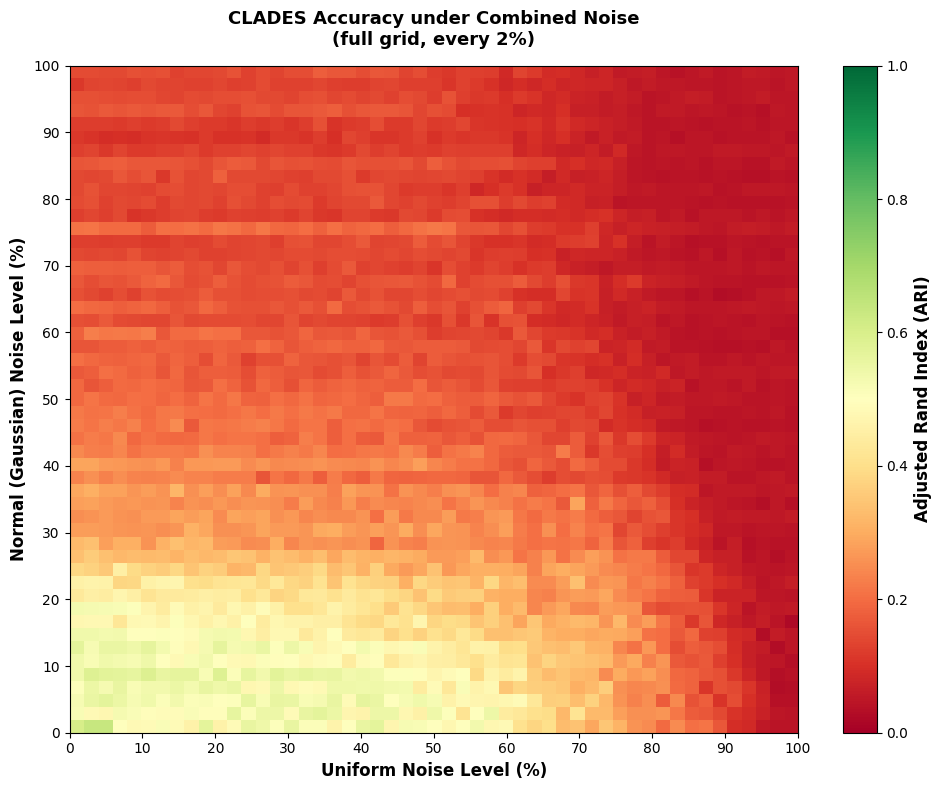

In [9]:
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(full_combined_grid, cmap='RdYlGn', origin='lower', vmin=0, vmax=1, 
               extent=[0, 100, 0, 100], aspect='auto')
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Adjusted Rand Index (ARI)", fontsize=12, fontweight='bold')

ax.set_xlabel("Uniform Noise Level (%)", fontsize=12, fontweight='bold')
ax.set_ylabel("Normal (Gaussian) Noise Level (%)", fontsize=12, fontweight='bold')
ax.set_title("CLADES Accuracy under Combined Noise\n(full grid, every 2%)", fontsize=13, fontweight='bold', pad=15)

# Add tick marks every 10%
ticks = list(range(0, 101, 10))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels([f"{x}" for x in ticks])
ax.set_yticklabels([f"{y}" for y in ticks])

plt.tight_layout()
plt.show()


### Save Results to CSV


In [10]:
# Save single noise results
single_df = pd.DataFrame({
    'noise_pct': all_levels,
    'normal_ari': full_normal_ari,
    'uniform_ari': full_uniform_ari
})
single_df.to_csv('simulated_data/clades_single_noise_ari_results.csv', index=False)
print("CLADES single noise results saved to simulated_data/clades_single_noise_ari_results.csv")

# Save combined noise grid
combined_df = pd.DataFrame(full_combined_grid, 
                           index=[f"Normal_{p}" for p in all_levels_combined],
                           columns=[f"Uniform_{p}" for p in all_levels_combined])
combined_df.to_csv('simulated_data/clades_combined_noise_ari_results.csv')
print("CLADES combined noise grid saved to simulated_data/clades_combined_noise_ari_results.csv")
print(f"Grid shape: {full_combined_grid.shape}")


CLADES single noise results saved to simulated_data/clades_single_noise_ari_results.csv
CLADES combined noise grid saved to simulated_data/clades_combined_noise_ari_results.csv
Grid shape: (51, 51)
